In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def loadData(folder, label, image_size=(32, 32)):
    data = []
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            path = os.path.join(folder, filename)
            try:
                img = Image.open(path).convert('RGB')
                img = img.resize(image_size)
                img_array = np.array(img).flatten() / 255.0
                data.append((img_array, label))
            except Exception as e:
                print(f"Eroare la {filename}: {e}")
    return data



normalData = loadData('photos', label=0)
sepiaData = loadData('photos_sepia', label=1)

allData = normalData + sepiaData
np.random.shuffle(allData)

inputs = [x[0] for x in allData]
outputs = [x[1] for x in allData]



In [2]:
def splitData(inputs_data, outputs_data):
    np.random.seed(5)
    indexes = [i for i in range(len(inputs_data))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs_data)), replace = False)
    testSample = [i for i in indexes  if not i in trainSample]

    trainInputs = [inputs_data[i] for i in trainSample]
    trainOutputs = [outputs_data[i] for i in trainSample]
    testInputs = [inputs_data[i] for i in testSample]
    testOutputs = [outputs_data[i] for i in testSample]

    return trainInputs, trainOutputs, testInputs, testOutputs

trainInputs, trainOutputs, testInputs, testOutputs = splitData(inputs, outputs)
print(f"Train set: {len(trainInputs)} imagini")
print(f"Test set: {len(testOutputs)} imagini")


Train set: 139 imagini
Test set: 35 imagini


Accuracy:  0.8285714285714286
Precision normal:  0.875
Precision sepia:  0.7894736842105263
Recall normal:  0.7777777777777778
Recall sepia:  0.8823529411764706


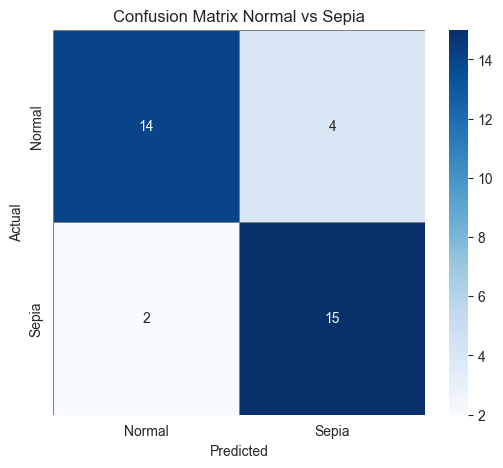

In [16]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
from ANN import ANN

classifier = ANN(input_size=len(trainInputs[0]), hidden_size=16, learning_rate=0.01, epochs=2000)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()



Accuracy:  0.6
Precision normal:  1.0
Precision sepia:  0.5483870967741935
Recall normal:  0.2222222222222222
Recall sepia:  1.0


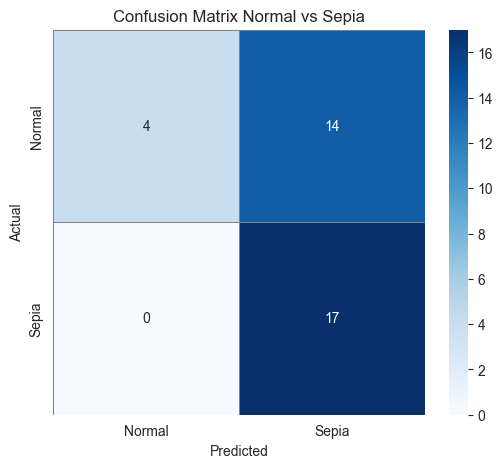

In [6]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
from ANN import ANN

classifier = ANN(input_size=len(trainInputs[0]), hidden_size=16, learning_rate=0.001, epochs=2000)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()



Accuracy:  0.4857142857142857
Precision normal:  0.0
Precision sepia:  0.4857142857142857
Recall normal:  0.0
Recall sepia:  1.0


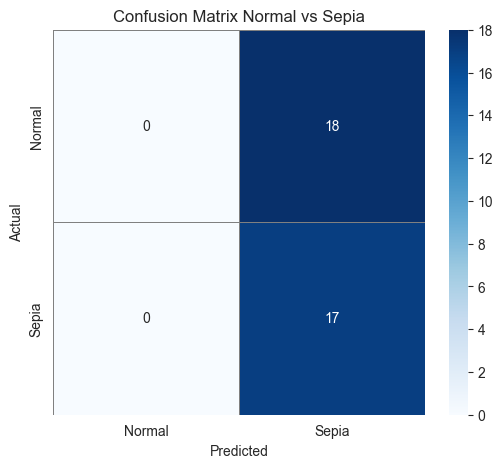

In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
from ANN import ANN

classifier = ANN(input_size=len(trainInputs[0]), hidden_size=16, learning_rate=0.1, epochs=2000)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()



Accuracy:  0.8
Precision normal:  1.0
Precision sepia:  0.7083333333333334
Recall normal:  0.6111111111111112
Recall sepia:  1.0


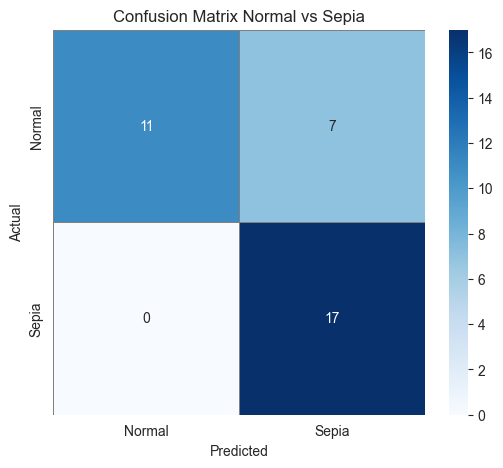

In [29]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
from ANN import ANN

classifier = ANN(input_size=len(trainInputs[0]), hidden_size=10, learning_rate=0.05, epochs=2000)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()

